<a href="https://colab.research.google.com/github/Seamuscs/Brent-and-WTI-spot-prices-spread/blob/main/Brent%20and%20WTI%20spot%20prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part I - History and basic analysis of oil spot prices**

The first part of this notebook, I pull data from the federal reserve and clean it, further I shall then do some basic statistical analysis by computing z-scores. I will detail the limitations of this, I will clear up one of the limitations by computing the inflated value of the dollar and update the values of the spot prices based on this. I will also give a brief summary of the notable parts of history that affected the price.


In [125]:
#preamble
import pandas as pd
import matplotlib.pyplot as plt

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}"
brent = pd.read_csv(url.format("DCOILBRENTEU"), index_col=0, parse_dates=True)
wti = pd.read_csv(url.format("DCOILWTICO"), index_col=0, parse_dates=True)

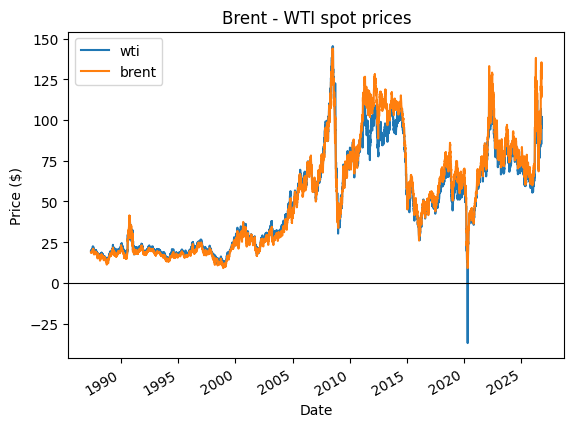

In [126]:
#cleaning data

df = pd.concat([wti, brent], axis=1, join="inner")
df.columns = ["wti", "brent"]
df.dropna(inplace=True)
bx = df.plot()
bx.set_title('Brent - WTI spot prices')
bx.set_xlabel("Date")
bx.set_ylabel("Price ($)")
bx.axhline(0, color="black", linewidth=0.8)
plt.show()
  #merge Brent and WTI and remove and days for both where prices are not available
  #plot both Brent and WTI on the same graph

Plot graphs the Brent and WTI spot prices independently. They more often than not move in unison apart from a select few cases. I shall now detail the historical structural breaks in the graph.

# 1990 - Gulf War

We see a brief rise in oil prices around 1990. This is due to the Gulf war in 1990 to 1991, the Gulf war triggered fear in the market and competition for less barrels of oil, this lead to the price per barrel increasing. However, this was short-lived as swift action by the 42-country coalition ended the invasion of Iraq into Kuwait and the fear evaporated, the price returned to pre-war levels.

# 1997 - Asian financial crisis

The Asian financial crisis caused a depreciation in oil prices. The consequence of the crash was that investors pulled their money out of Asia. Countries like Thailand, Indonesia and South Korea were most effected and led to oil demand in those countries falling. At the same time, OPEC had recently increased their output meaning prices fell even more so. It also meant OPEC countries also faced economic difficulties, the Asian financial crisis quickly affected anyone with major oil exports as demand had been cut.

# 2000s -  Global financial crisis

The Asian financial crisis was very harsh but also quite short lived. In response to the crash, OPEC countries agreed to cut the supply they had just raised. The surplus had also been stored away, now with supply capped and demand finally increased again after the financial crisis, prices increased in the turn of the century.

Another surge in around 2000-2002 after the small surge was due to the preemptive war premium the market priced. A few years earlier, the fatal attack of 9/11 led to a change in foreign polict in the United States. In 2003, the USA, deployed in Iraq, in the war time economy, supply stagnated and so prices shot up as the market priced for war and to capitalise on it. From here on also China and India were two of the fastes growing and rapidly industrialising economies in the world. With vast populations, their rapid industrialisation became a glut for crude oil. Demand through this time absolutely sky-rocketted to nearly 150 USD per barrel, a record high.

Though, this was incredibly short lived as the global financial crisis hit, causing the price of oil to go from that record high right down to about 25 USD per barrel in a month. The global financial crash. It was catastrophic, it was caused by the US housing market collapsing. Houses are often used as collateral for loans, when the market is less certain, banks require higher collateral against loans and so they just ceased lending all together and sold their houses. This caused the already failing house market to fall harder. It caused a global recession and the price of oil along with everything else collapsed.

The price quickly bounced back up though, this is due to OPEC cutting the number of barrels it produced and the stored amount of oil started to drain after the financial crisis which pushed prices up sharply again.

# 2011 - Libyan civil war

This is our second meaningful deviation between the two benchmarks. In 2011, Brent was sold at a premium relative to WTI. This is mainly due to two reasons. The first reason is the civil war in Libya. Libya mainly produced light and sweet oil, oil production ceased to near zero in the civil war which meaninfully pushed the global price up, for both benchmarks, WTI not as much though relative to Brent. This is because WTI has its own issues. Unlike Brent, which is offshore, WTI is inland and is required to be held in storage containers at Cushing. Storage and pipelines are not infinite in supply, only so much oil can be held at a given time and pipelines have a maximum discharge in any one direction. The issue was most pipelines went inland, the USA till this point was a large importer of oil instead of exporter. This meant that when there was a glut of oil at cushing, it was not able to sell it effectively as the infrastracture to sell large amounts of oil simply was not there. This lead to the WTI price trading at a discount compared to Brent at the time.

# 2014 - Shale boom

The first thing to note is since 2011, the issues regarding cushing had mostly been fixed, oil could now be moved both ways rather seemlessly, so now Brent and WTI were coherent again. The event that drove prices down this time was the oversupply of crude drilled from shale rock, hence the name Shale Boom. The large supply of shale oil entering the market rapidly caused Brent and WTI to fall simultaneously. OPEC also decided not to cut production and ultimately tried to compete with the US shale market as before it had lost considerable market share to defend its prices. Though this changed in around 2016 when they finally cut production and oil prices increased to some extent.

I feel it is also important to note a change in what the price of oil should be. Before the turn of the century, spot prices as seen in the data traded around 20 USD per barrel, but as we just saw, OPEC pushed the price up on purpose in 2016. This reflects what the new 'normal' price of oil is, at this time it was around 65-70 USD per barrel. This is a significant change and I will speak later about how this points as a limitation of any modelling I do.

# 2020 - Covid and Cushing

This is the most important and confusing results we find. You see immediately that the price of WTI, falls below 0 USD per barrel, infact to around -37 USD per barrel. It was a massive accumulation of two factors. The Covid-19 pandemic caused a lack of demand the oil industry simply had never seen before aside from the global financial crisis. No one wanted to buy oil, no one was travelling aside from essential travel, so there was no real demand for petroleum, a large reason why crude is refined in the first place. This obviously hit both benchmarks hard, though WTI was hit much harder. Brent could still sell, it was just that new drilling was not happening. The price of brent dropped to about 10 USD per barrel, bad but not catastrophic. However, with WTI, with little demand for oil for several months, the storage of WTI filled up. Cushing was near full, with little to no storage space, buyers demanded to be paid to take the oil off their hands and the price was settled historically at -37.63 USD on the 20th of April 2020. As per many times before this, Brent is not affected as much as it simply only relies on how mc=uch tankers could fit, though this was still a small sticking point as less tankers would mean that tankers get more full, though this was never catastrophic unlike WTI's problem.

This was short-lived however as China emerged from the pandemic first and so demand went back up. Global oil production was also held much lower so prices naturally increased as WTI's storage drained and demand went up.

# 2022 -  Russian invasion

Soon after the Covid-19 pandemic, Russia invaded Ukraine of which is still ongoing. With Russia being one of the largest exporters of oil, the fear of losing the oil caused prices to go up. Though more than this, European refineries later banned russian oil which is a large percentage of european meaning to get the same type of oil, they turned to WTI, which was being sold at Brent prices to the European market, the increased competition led to Brent's price inflating. Moving WTI oil to Europe also costs money, the abritrage also pushed up the price of the benchmark.

The price eventually went back as the fear the market had never materialised as Russian oil was mostly just sold to other countries instead and so prices deflated.

# 2026 - Iranian conflict

Till recently, oil prices were in a stable decline. This changed effective immeadiately, caused by the US invasion of Iran. Iran in response shut the Strate of Hormuz. The Strate of Hormuz is chicane in one of the world's busiest shipping lanes. Any seaborne freight from Europe to Asia, goes through the Suez Canal and then the Strate of Hormuz. This closure meant no loaded tankers were getting through. The lack of supply, moreso the supply being blocked, led to a huge spike in the price of oil though more notably Brent. Again, this is due to Brent being seaborne crude and is only traded through the sea. As a large amount of the demand is in Asia or just through that shipping route in general, Brent just was not being sold at the rate it was before. WTI on the other hand is mostly inland aside from some exported elsewhere which is why the price spiked for WTI, just not as much.

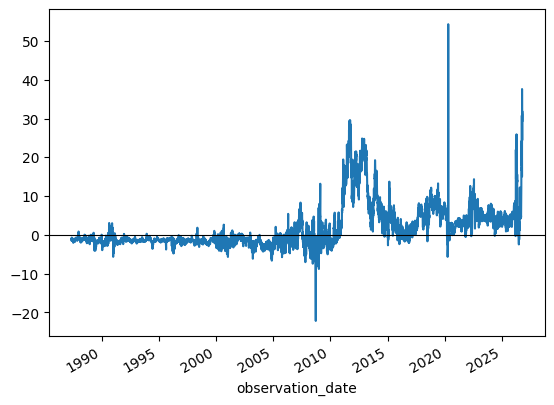

                     wti   brent  spread  spread_zscore
observation_date                                       
1987-05-20         19.75   18.63   -1.12      -0.592712
1987-05-21         19.95   18.45   -1.50      -0.659679
1987-05-22         19.68   18.55   -1.13      -0.594474
1987-05-26         19.35   18.63   -0.72      -0.522221
1987-05-27         19.38   18.60   -0.78      -0.532795
...                  ...     ...     ...            ...
2026-10-08         98.26  130.18   31.92       5.229846
2026-10-09         98.73  130.03   31.30       5.120585
2026-10-12         98.73  129.95   31.22       5.106487
2026-10-13        100.86  125.78   24.92       3.996253
2026-10-14        101.91  126.55   24.64       3.946909

[8416 rows x 4 columns]


In [127]:
#analysis
df["spread"] = df["brent"] - df["wti"]
ax = df["spread"].plot()
ax.axhline(0, color="black", linewidth=0.8)
plt.show()
  #Caclulate spread by subtraction WTI from Brent and plotting it to see

useful = df["spread"].describe()
all_time_mean = useful['mean']
all_time_std = useful['std']
spread_zscore = (df["spread"] - all_time_mean) / all_time_std
spread_zscore.name = "spread_zscore"
df = pd.concat([df, spread_zscore], axis=1)
print(df)
  #Use the describe function to calcualte all-time mean and standard deviation, calculate z-score at each spot

The spread shows us the difference in price between the two oil benchmarks. Most of the time the spread oscillates around a mean, which itself changes on the period, apart from a few incidents which can be explained from the spot prices in the section before.

 # Limitations

 Calculating z-scores is a good way of seeing just how far a data point lies from the mean. Though, calculating this from the mean of whole data set is not always a good conclusion. This is because attitudes to what oil should be traded at changes over time. As I pointed out earlier, oil was traded at a higher price over the turn of the century. Calculating, earlier prices from this 'all-time mean' would suggest that all oil prices pre-2000 are all under what you see as an acceptable spread. This is why the 'all-time mean' is not always suitable, especially with how real world geopolitics shapes the price of oil. More appropriately you could choose, within reason when to calculate different means. Pre-2008, you could suggest a mean of around -1 to -2 USD per barrel, whereas after it would be more acceptable to choose a new mean as from then on Brent is traded at a premium. Though, we can see the spread to be mostly stable aside a few later events. The idea of a changing mean would be more prudent for the spot price of individual benchmarks, though it would not hurt to use it on the spread too. There are ways to do this through a rolling mean.

 Another issue we have is that we are looking at spot prices. In the real world, oil is traded with futures instead of spot prices. Analysing spot prices is fine in hindsight, to look at why things move but to actually calculate worthwhile statistics we would want to use futures instead.

 The other issue is that one USD in 1990 say, is not worth the same as one USD in 2026. I can therefore make two plots accounting for inflation below but it will show the true size of the structural breaks but in today's money. I will now on use the adjusted for inflation data for further calculations.

                     wti   brent  spread  spread_zscore  Purchasing Power  \
observation_date                                                            
1987-05-20         19.75   18.63   -1.12      -0.592712              88.4   
1987-05-21         19.95   18.45   -1.50      -0.659679              88.4   
1987-05-22         19.68   18.55   -1.13      -0.594474              88.4   
1987-05-26         19.35   18.63   -0.72      -0.522221              88.4   
1987-05-27         19.38   18.60   -0.78      -0.532795              88.4   
...                  ...     ...     ...            ...               ...   
2026-10-08         98.26  130.18   31.92       5.229846              29.7   
2026-10-09         98.73  130.03   31.30       5.120585              29.7   
2026-10-12         98.73  129.95   31.22       5.106487              29.7   
2026-10-13        100.86  125.78   24.92       3.996253              29.7   
2026-10-14        101.91  126.55   24.64       3.946909              29.7   

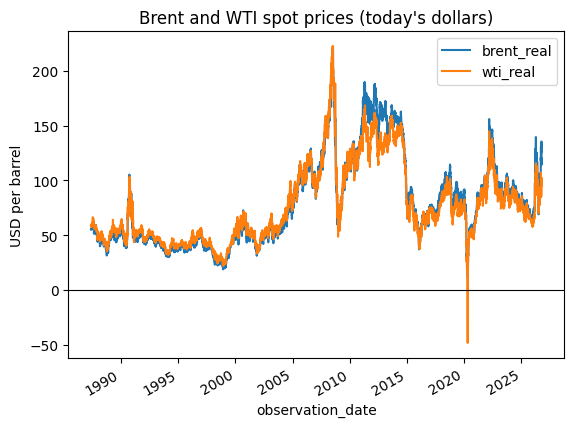

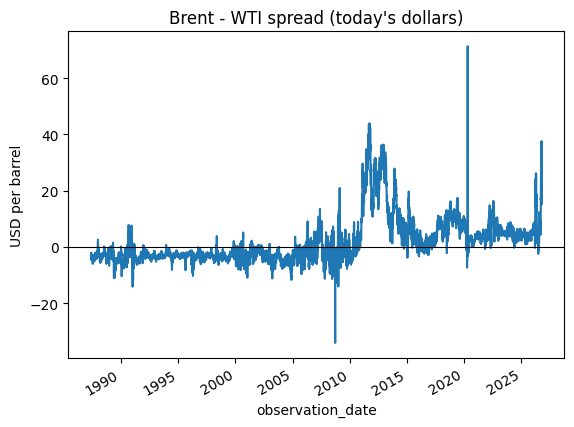

In [128]:
url_1 = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CUUR0000SA0R"
PP = pd.read_csv(url_1, index_col=0, parse_dates=True)
PP.columns = ["Purchasing Power"]

# spread each monthly value across the days of that month
df["Purchasing Power"] = PP["Purchasing Power"].reindex(df.index, method="ffill")
df["Conversion Rate"] = df["Purchasing Power"] / df["Purchasing Power"].iloc[-1]

# real (today's dollars) columns, keeping the nominal ones
df["wti_real"] = df["wti"] * df["Conversion Rate"]
df["brent_real"] = df["brent"] * df["Conversion Rate"]
df["spread_real"] = df["brent_real"] - df["wti_real"]

useful_ad = df["spread_real"].describe()
df["spread_zscore_real"] = (df["spread_real"] - useful_ad["mean"]) / useful_ad["std"]
print(df)

dx = df[["brent_real", "wti_real"]].plot()
dx.set_title("Brent and WTI spot prices (today's dollars)")
dx.set_ylabel("USD per barrel")
dx.axhline(0, color="black", linewidth=0.8)
plt.show()

cx = df["spread_real"].plot()
cx.set_title("Brent - WTI spread (today's dollars)")
cx.set_ylabel("USD per barrel")
cx.axhline(0, color="black", linewidth=0.8)
plt.show()

# **Part II - Statistical Analysis**

Further additions will be made in due course